# Evaluación y comparativa de modelos

Consolida los resultados de todos los bloques del equipo leyendo dinámicamente los archivos del enfoque elegido:

* `reports/metrics_*.csv` → comparativa de **F1 macro** (test 20% y validación cruzada de 5 folds).
* `reports/adversarial_results.csv` → robustez frente al banco adversarial.
* `data/vectorized/y_pred_*.npy` (o el modelo `.joblib` si no hay predicciones guardadas) → **matrices de confusión**.
* `reports/learning_curve_*.csv` → **curvas de aprendizaje**.

Cambiando `ENFOQUE` a `"biclase"` se obtiene la misma evaluación para el flujo binario. Si un bloque nuevo exporta sus archivos con el contrato de nombres, aparece automáticamente.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import sparse
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, learning_curve

# Enfoque a evaluar: "triclase" (por defecto) o "biclase".
ENFOQUE = "triclase"
CLASS_NAMES = {"triclase": ["Negativo", "Neutral", "Positivo"], "biclase": ["Negativo", "Positivo"]}[ENFOQUE]

# Raiz del repo detectada desde cualquier carpeta de ejecucion del notebook.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
BASE = ROOT / ENFOQUE
REPORTS, VECTORIZED, MODELS = BASE / "reports", BASE / "data" / "vectorized", BASE / "models"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Modelos extra para curvas de aprendizaje calculadas aca (bloque, modelo, representacion), con cache en CSV.
EXTRA_LEARNING_CURVES = [("linear", "logreg", "tfidf_bigram")]
RANDOM_STATE, CV_FOLDS = 42, 5

sns.set_theme(style="whitegrid")
y_test = np.load(VECTORIZED / "y_test.npy")

## 1. Consolidación de métricas

In [2]:
# Une todas las tablas metrics_<bloque>.csv agregando el bloque de origen.
metrics = pd.concat(
    [pd.read_csv(path).assign(block=path.stem.removeprefix("metrics_")) for path in sorted(REPORTS.glob("metrics_*.csv"))],
    ignore_index=True,
)
metrics["label"] = metrics["model"].str.split("/").str[-1] + " · " + metrics["representation"]
metrics = metrics.sort_values("f1_macro", ascending=False).reset_index(drop=True)
metrics.round(4)

,model,representation,accuracy,precision_macro,recall_macro,f1_macro,cv_f1_mean,cv_f1_std,block,label
0,sgdopt,tfidfoptsgd,0.7212,0.6610,0.6573,0.6567,0.6566,0.0044,opt,sgdopt · tfidfoptsgd
1,logregopt,bowoptlogreg,0.6941,0.6554,0.6539,0.6530,0.6554,0.0024,opt,logregopt · bowoptlogreg
2,compnbopt,tfidfoptnb,0.6968,0.6412,0.6410,0.6408,0.6396,0.0041,opt,compnbopt · tfidfoptnb
3,logreg,tfidf_bigram,0.7278,0.6593,0.6463,0.6396,0.6366,0.0035,linear,logreg · tfidf_bigram
4,linearsvc,tfidf_bigram,0.7100,0.6373,0.6335,0.6283,0.6268,0.0035,linear,linearsvc · tfidf_bigram
5,logreg,tfidf_unigram,0.7092,0.6397,0.6264,0.6175,0.6150,0.0026,linear,logreg · tfidf_unigram
6,cardiffnlp/twitter-roberta-base-sentiment-latest,hf_pipeline,0.6994,0.6194,0.6225,0.6173,NaN,NaN,hf,twitter-roberta-base-sentiment-latest · hf_pip...
7,linearsvcopt,tfidfoptsvc,0.7298,0.6627,0.6349,0.6172,0.6156,0.0029,opt,linearsvcopt · tfidfoptsvc
8,nb,bow,0.6757,0.6146,0.6138,0.6125,0.6125,0.0028,linear,nb · bow
9,logreg,bow,0.6988,0.6249,0.6178,0.6094,0.6078,0.0012,linear,logreg · bow


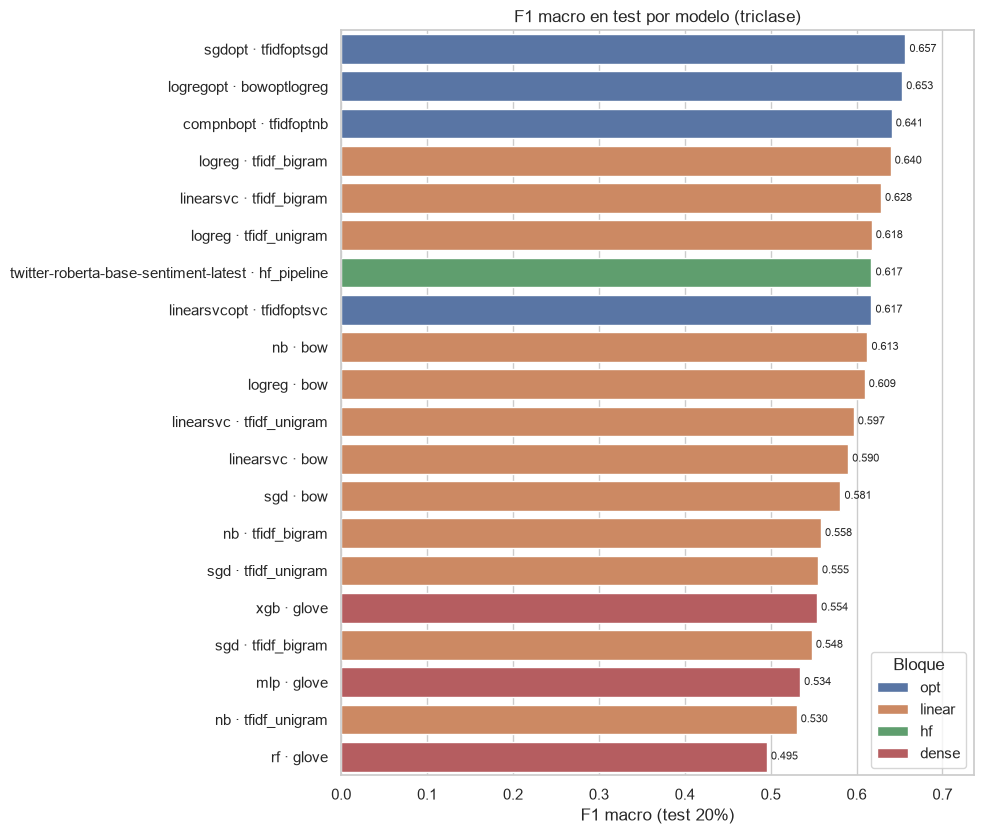

In [3]:
# Comparativa de F1 macro en test para todos los modelos, coloreada por bloque.
fig, ax = plt.subplots(figsize=(10, 0.35 * len(metrics) + 1.5))
sns.barplot(data=metrics, y="label", x="f1_macro", hue="block", dodge=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=8)
ax.set(title=f"F1 macro en test por modelo ({ENFOQUE})", xlabel="F1 macro (test 20%)", ylabel="", xlim=(0, metrics["f1_macro"].max() + 0.08))
ax.legend(title="Bloque", loc="lower right")
plt.tight_layout()
fig.savefig(FIGURES / "f1_macro_comparison_all.png", dpi=150, bbox_inches="tight")
plt.show()

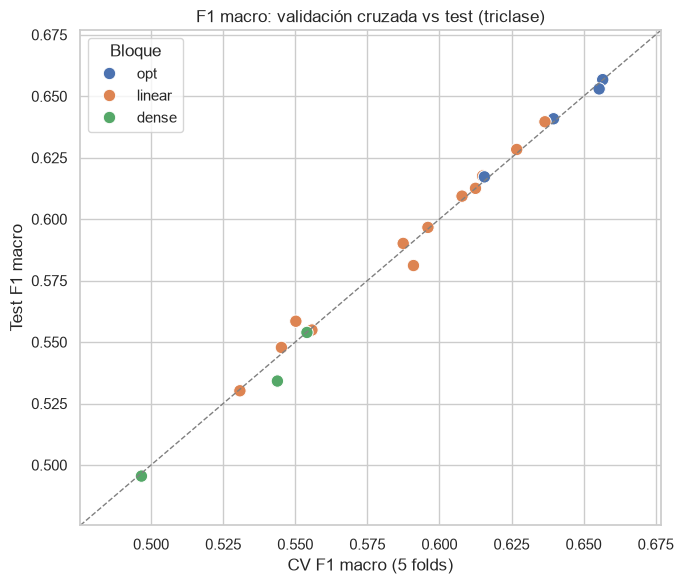

In [4]:
# Test vs validacion cruzada: puntos sobre la diagonal indican que el modelo generaliza sin sobreajuste.
cv_rows = metrics.dropna(subset=["cv_f1_mean"])
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=cv_rows, x="cv_f1_mean", y="f1_macro", hue="block", s=80, ax=ax)
limits = [cv_rows[["cv_f1_mean", "f1_macro"]].min().min() - 0.02, cv_rows[["cv_f1_mean", "f1_macro"]].max().max() + 0.02]
ax.plot(limits, limits, "--", color="gray", linewidth=1)
ax.set(title=f"F1 macro: validación cruzada vs test ({ENFOQUE})", xlabel="CV F1 macro (5 folds)", ylabel="Test F1 macro", xlim=limits, ylim=limits)
ax.legend(title="Bloque")
plt.tight_layout()
fig.savefig(FIGURES / "cv_vs_test_f1.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Robustez frente al banco adversarial

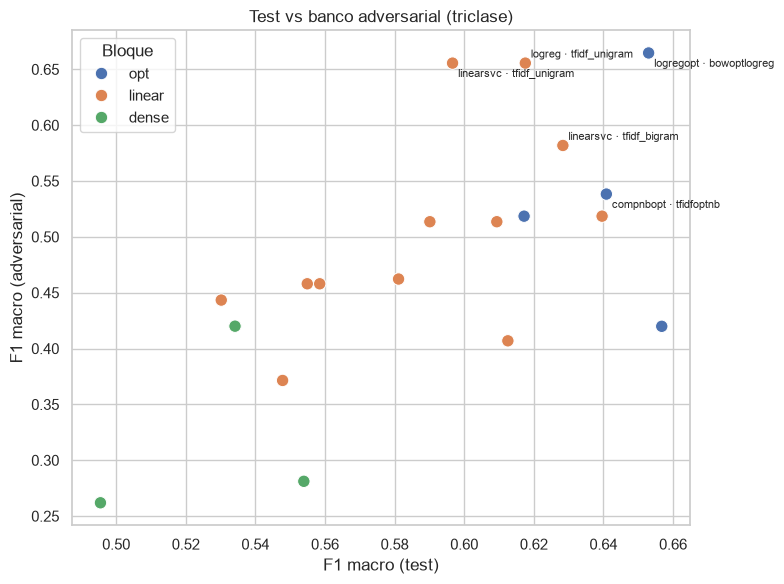

,block,label,f1_macro,adversarial_f1,drop
1,opt,logregopt · bowoptlogreg,0.6530,0.6646,-0.0117
9,linear,linearsvc · tfidf_unigram,0.5966,0.6556,-0.0589
5,linear,logreg · tfidf_unigram,0.6175,0.6556,-0.0380
4,linear,linearsvc · tfidf_bigram,0.6283,0.5818,0.0465
2,opt,compnbopt · tfidfoptnb,0.6408,0.5383,0.1025
6,opt,linearsvcopt · tfidfoptsvc,0.6172,0.5185,0.0987
3,linear,logreg · tfidf_bigram,0.6396,0.5185,0.1211
10,linear,linearsvc · bow,0.5901,0.5135,0.0766
8,linear,logreg · bow,0.6094,0.5135,0.0958
11,linear,sgd · bow,0.5811,0.4622,0.1189


In [5]:
# Cruce entre el F1 del test y el F1 sobre el banco adversarial (si ya se ejecuto evaluate_adversarial.py).
adversarial_path = REPORTS / "adversarial_results.csv"
if adversarial_path.exists():
    adversarial = pd.read_csv(adversarial_path).rename(columns={"f1_macro": "adversarial_f1"})
    robustness = metrics.merge(adversarial[["model", "representation", "adversarial_f1"]], on=["model", "representation"])
    robustness["drop"] = robustness["f1_macro"] - robustness["adversarial_f1"]

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(data=robustness, x="f1_macro", y="adversarial_f1", hue="block", s=80, ax=ax)
    # Etiquetas de los 5 mas robustos con desplazamiento alternado para que no se superpongan.
    for i, (_, row) in enumerate(robustness.nlargest(5, "adversarial_f1").iterrows()):
        ax.annotate(row["label"], (row["f1_macro"], row["adversarial_f1"]), fontsize=8, xytext=(4, 4 if i % 2 else -10), textcoords="offset points")
    ax.set(title=f"Test vs banco adversarial ({ENFOQUE})", xlabel="F1 macro (test)", ylabel="F1 macro (adversarial)")
    ax.legend(title="Bloque")
    plt.tight_layout()
    fig.savefig(FIGURES / "test_vs_adversarial_f1.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(robustness[["block", "label", "f1_macro", "adversarial_f1", "drop"]].sort_values("adversarial_f1", ascending=False).round(4))
else:
    print(f"No se encontro {adversarial_path}. Ejecutar evaluate_adversarial.py para incluir esta seccion.")

## 3. Matrices de confusión del mejor modelo de cada bloque

Se normalizan por fila: la diagonal es el *recall* de cada clase, lo que deja ver cuánto le cuesta a cada enfoque la clase neutral.

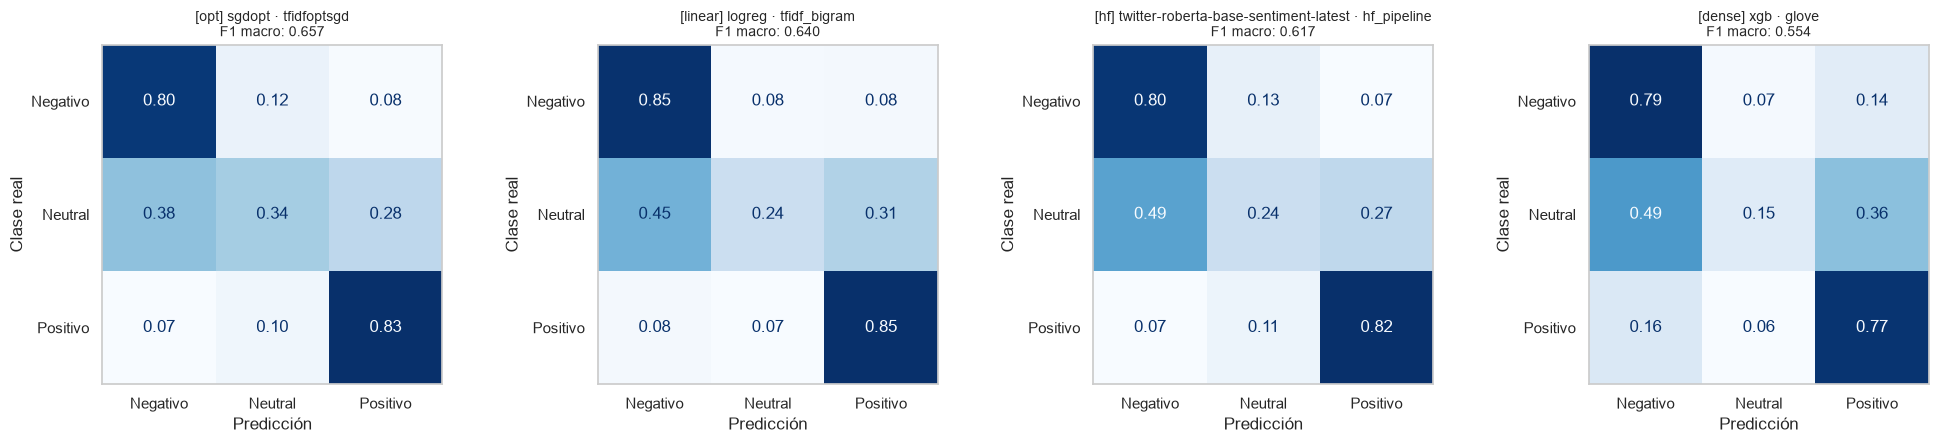

In [6]:
def get_predictions(row):
    # Busca predicciones guardadas; si no existen, las genera con el modelo y la matriz de test y las cachea.
    candidates = [f"y_pred_{row.block}_{row.model}.npy", f"y_pred_{row.block}.npy", f"y_pred_{row.block}_{row.model}_{row.representation}.npy"]
    for name in candidates:
        if (VECTORIZED / name).exists():
            return np.load(VECTORIZED / name)

    model_path = MODELS / f"model_{row.model}_{row.representation}.joblib"
    sparse_path, dense_path = VECTORIZED / f"X_test_{row.representation}.npz", VECTORIZED / f"X_test_{row.representation}.npy"
    x_path = sparse_path if sparse_path.exists() else dense_path
    if not (model_path.exists() and x_path.exists()):
        return None
    x_test = sparse.load_npz(x_path) if x_path.suffix == ".npz" else np.load(x_path)
    y_pred = joblib.load(model_path).predict(x_test)
    np.save(VECTORIZED / candidates[-1], y_pred)
    return y_pred


# Mejor modelo de cada bloque que tenga predicciones disponibles.
best_rows = [(row, y_pred) for _, row in metrics.groupby("block", sort=False).head(1).iterrows() if (y_pred := get_predictions(row)) is not None]

fig, axes = plt.subplots(1, len(best_rows), figsize=(5 * len(best_rows), 4.5), squeeze=False)
for ax, (row, y_pred) in zip(axes[0], best_rows):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES, normalize="true", values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"[{row.block}] {row.label}\nF1 macro: {row.f1_macro:.3f}", fontsize=10)
    ax.set(xlabel="Predicción", ylabel="Clase real")
    ax.grid(False)
plt.tight_layout()
fig.savefig(FIGURES / "confusion_matrices_best_per_block.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Curvas de aprendizaje

F1 macro en entrenamiento y validación (5 folds) a medida que crece el train. Una brecha grande indica sobreajuste; curvas juntas y planas indican que más datos no mejorarían al modelo.

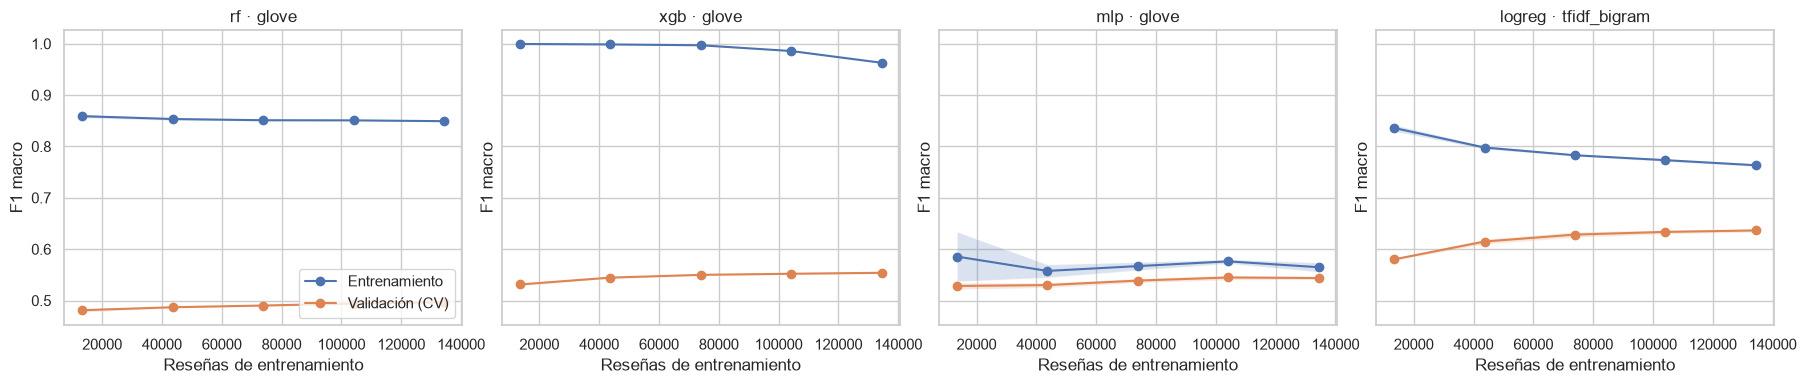

In [7]:
def compute_learning_curve(block, model_name, representation):
    # Curva de aprendizaje de un modelo ya entrenado (mismos hiperparametros), cacheada en reports/.
    cache = REPORTS / f"learning_curve_{block}.csv"
    model_path = MODELS / f"model_{model_name}_{representation}.joblib"
    x_path = VECTORIZED / f"X_train_{representation}.npz"
    if cache.exists() or not (model_path.exists() and x_path.exists()):
        return
    splitter = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    sizes, train_scores, val_scores = learning_curve(
        clone(joblib.load(model_path)), sparse.load_npz(x_path), np.load(VECTORIZED / "y_train.npy"),
        train_sizes=np.linspace(0.1, 1.0, 5), cv=splitter, scoring="f1_macro", n_jobs=-1, shuffle=True, random_state=RANDOM_STATE,
    )
    pd.DataFrame({
        "model": model_name, "representation": representation, "train_size": sizes,
        "train_f1_mean": train_scores.mean(axis=1), "train_f1_std": train_scores.std(axis=1),
        "val_f1_mean": val_scores.mean(axis=1), "val_f1_std": val_scores.std(axis=1),
    }).round(6).to_csv(cache, index=False)


for extra in EXTRA_LEARNING_CURVES:
    compute_learning_curve(*extra)

curves = pd.concat([pd.read_csv(path) for path in sorted(REPORTS.glob("learning_curve_*.csv"))], ignore_index=True)
curve_groups = list(curves.groupby(["model", "representation"], sort=False))

fig, axes = plt.subplots(1, len(curve_groups), figsize=(4.5 * len(curve_groups), 4), sharey=True, squeeze=False)
for ax, ((model_name, representation), curve) in zip(axes[0], curve_groups):
    for prefix, label in (("train", "Entrenamiento"), ("val", "Validación (CV)")):
        ax.plot(curve["train_size"], curve[f"{prefix}_f1_mean"], marker="o", label=label)
        ax.fill_between(curve["train_size"], curve[f"{prefix}_f1_mean"] - curve[f"{prefix}_f1_std"], curve[f"{prefix}_f1_mean"] + curve[f"{prefix}_f1_std"], alpha=0.2)
    ax.set(title=f"{model_name} · {representation}", xlabel="Reseñas de entrenamiento", ylabel="F1 macro")
axes[0][0].legend(loc="lower right")
plt.tight_layout()
fig.savefig(FIGURES / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Resumen

In [8]:
# Lider global en test y mejor modelo de cada bloque.
leaders = metrics.groupby("block", sort=False).head(1)[["block", "model", "representation", "accuracy", "f1_macro", "cv_f1_mean"]]
print(f"Lider global en test ({ENFOQUE}): {metrics.loc[0, 'label']} | F1 macro = {metrics.loc[0, 'f1_macro']:.4f}")
leaders.round(4)

Lider global en test (triclase): sgdopt · tfidfoptsgd | F1 macro = 0.6567


,block,model,representation,accuracy,f1_macro,cv_f1_mean
0,opt,sgdopt,tfidfoptsgd,0.7212,0.6567,0.6566
3,linear,logreg,tfidf_bigram,0.7278,0.6396,0.6366
6,hf,cardiffnlp/twitter-roberta-base-sentiment-latest,hf_pipeline,0.6994,0.6173,NaN
15,dense,xgb,glove,0.6538,0.5539,0.5541
